## Project Objective: Cars24 – Used Car Market Analysis & Price Intelligence
The main objective of this project is to collect, clean, and analyse used car listing data from Cars24 using Python and web scraping techniques. The project aims to identify pricing trends, understand the relationship between car features and resale prices, and discover factors influencing used car prices.

The analysis focuses on:
- Understanding used car market trends.
- Comparing average prices across different car brands.
- Analysing the impact of manufacturing year and car age on resale prices.
- Studying the relationship between kilometres driven and car prices.
- Comparing prices based on fuel type and transmission.
- Identifying expensive and affordable car models.
- Generating meaningful business insights to support better used car buying and selling decisions.

In [2]:
!pip install pandas numpy matplotlib seaborn requests beautifulsoup4 selenium

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup
import re

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
import requests

url = "https://www.cars24.com/buy-used-cars/"

response = requests.get(url)

print("Status Code:", response.status_code)
print("Website:", response.url)

Status Code: 200
Website: https://www.cars24.com/buy-used-cars/


In [9]:
from bs4 import BeautifulSoup

soup = BeautifulSoup(response.text, "html.parser")

# Extract website title
print("Website Title:", soup.title.text)

# Check HTML content length
print("HTML Length:", len(response.text))

# Extract some visible text
page_text = soup.get_text(separator=" ", strip=True)

print("\nWebsite Content:")
print(page_text[:2000])

Website Title: Buy Used Cars Online - Second Hand Cars In India | Cars24
HTML Length: 1456374

Website Content:
Buy Used Cars Online - Second Hand Cars In India | Cars24 Buy used car Buy Used Cars in India Change city Browse by City Browse by City Used Cars in Delhi NCR Used Cars in Bangalore Used Cars in New Delhi Used Cars in Hyderabad Used Cars in Mumbai Used Cars in Pune Used Cars in Ahmedabad Used Cars in Chennai Used Cars in Gurgaon Used Cars in Noida Used Cars in Lucknow Used Cars in Ghaziabad Used Cars in Kolkata Used Cars in Jaipur Used Cars in Faridabad Buy cars online Sell car Sell car Used car valuation Sell car in Delhi Sell car in Mumbai Sell car in Bangalore Sell car in Hyderabad Sell car in Ahmedabad Sell car in Gurgaon Sell car in Chennai Sell car in Pune Sell car in Noida Sell car in Ghaziabad Sell car in Lucknow Sell car in Jaipur Sell car in Kolkata Sell car in Kochi Sell car in Indore Car finance Used car loan Loan against car Personal loan Credit cards Used car lo

In [12]:


# Find all script tags
scripts = soup.find_all("script")

print("Total Script Tags:", len(scripts))

# Search scripts for car-related keywords
keywords = ["price", "kmDriven", "carName", "model", "mileage"]

for i, script in enumerate(scripts):
    content = script.string or script.get_text()

    if content and any(word.lower() in content.lower() for word in keywords):
        print(f"\nScript Number: {i}")
        print(content[:1000])


Total Script Tags: 85

Script Number: 45
self.__next_f.push([1,"23:[[\"$\",\"meta\",\"0\",{\"name\":\"viewport\",\"content\":\"width=device-width, initial-scale=1, maximum-scale=5, user-scalable=yes\"}],[\"$\",\"meta\",\"1\",{\"charSet\":\"utf-8\"}],[\"$\",\"title\",\"2\",{\"children\":\"Buy Used Cars Online - Second Hand Cars In India | Cars24\"}],[\"$\",\"meta\",\"3\",{\"name\":\"description\",\"content\":\"Buy best used cars online in India - Cars24.com offers 100% verified second-hand customer cars at best price with Easy Finance and RC Transfer.\"}],[\"$\",\"meta\",\"4\",{\"name\":\"keywords\",\"content\":\"Buy used cars, buy used cars online, buy used cars online in India, Used Cars Online, Used Cars Online in India, Second Hand Cars, Second Hand Cars Online, Second Hand Cars Online in India, Buy Second hand cars online in India, Certified Used Cars, Pre-owned cars online in India\"}],[\"$\",\"meta\",\"5\",{\"name\":\"robots\",\"content\":\"INDEX,FOLLOW\"}],[\"$\",\"link\",\"6\",

In [13]:
# Search for important keywords inside all scripts

keywords = [
    "preloadedState",
    "usedCarHome",
    "carList",
    "carDetails",
    "listing",
    "price",
    "kmDriven",
    "fuelType",
    "transmission"
]

for i, script in enumerate(scripts):

    content = script.string or script.get_text()

    if content:
        found = [word for word in keywords if word.lower() in content.lower()]

        if found:
            print(f"\nScript Number: {i}")
            print("Keywords Found:", found)
            print("Script Length:", len(content))


Script Number: 45
Keywords Found: ['price']
Script Length: 3143

Script Number: 52
Keywords Found: ['price']
Script Length: 3382

Script Number: 53
Keywords Found: ['carList', 'carDetails', 'listing', 'price']
Script Length: 363372

Script Number: 60
Keywords Found: ['price']
Script Length: 2333

Script Number: 61
Keywords Found: ['price']
Script Length: 2426

Script Number: 63
Keywords Found: ['price']
Script Length: 2402

Script Number: 65
Keywords Found: ['price']
Script Length: 3382

Script Number: 67
Keywords Found: ['usedCarHome', 'carList', 'carDetails', 'listing', 'price', 'fuelType', 'transmission']
Script Length: 311832

Script Number: 76
Keywords Found: ['transmission']
Script Length: 2254

Script Number: 78
Keywords Found: ['preloadedState', 'usedCarHome', 'carList', 'carDetails', 'listing', 'price', 'fuelType', 'transmission']
Script Length: 588235

Script Number: 81
Keywords Found: ['listing', 'price', 'transmission']
Script Length: 6383


In [14]:
import re

# Select script 78
content = scripts[78].string or scripts[78].get_text()

# Search for important keywords
keywords = [
    "carList",
    "carDetails",
    "fuelType",
    "transmission",
    "kmDriven",
    "price"
]

for keyword in keywords:

    matches = list(re.finditer(keyword, content, re.IGNORECASE))

    print(f"\n{'='*40}")
    print(f"Keyword: {keyword}")
    print(f"Occurrences: {len(matches)}")

    for match in matches[:2]:

        start = max(0, match.start() - 200)
        end = min(len(content), match.end() + 500)

        print(content[start:end])


Keyword: carList
Occurrences: 22
\"altText\":\"A whole new world of cars\"},\"popUpDetails\":\"\"},\"POPUP_IMAGE\":{\"type\":\"\",\"url\":\"\",\"meta\":{}},\"POPUP_LOGO\":{\"type\":\"\",\"url\":\"\",\"meta\":{}}},\"metaInfo\":{}}],\"carListOffset\":0,\"totalElementsIncludingWidget\":0},\"children\":[],\"buName\":\"\",\"remove\":false},{\"key\":\"USED_CAR_INDIA_HOMEPAGE_DESCRIPTION\",\"meta\":{},\"sectionType\":\"Other\",\"viewType\":\"DESCRIPTION_STATIC_TEXT\",\"version\":1,\"title\":\"A whole new world of buying cars\",\"description\":\"Explore a huge inventory of high-quality, certified second-hand cars in India, from popular brands like Maruti Suzuki, Hyundai, Honda, and more. Our extensive list of used cars in India includes m
popular brands like Maruti Suzuki, Hyundai, Honda, and more. Our extensive list of used cars in India includes models like the Swift, i10 Nios, City, Kwid, and many more.\",\"data\":{\"content\":[],\"carListOffset\":0,\"totalElementsIncludingWidget\":0},\"ch

In [15]:
{
    "listingPrice": 416670,
    "originalPrice": 40680,
    "carName": "Hyundai Grand i10",
    "make": "Hyundai",
    "model": "Grand i10",
    "variant": "MAGNA 1.2 KAPPA VTVT",
    "year": 2018,
    "transmissionType": {
        "value": "Manual"
    },
    "bodyType": "Hatchback",
    "fuelType": "Petrol",
    "ownership": 1,
    "odometer": {
        "value": 55214,
        "display": "55,214 km"
    }
}

{'listingPrice': 416670,
 'originalPrice': 40680,
 'carName': 'Hyundai Grand i10',
 'make': 'Hyundai',
 'model': 'Grand i10',
 'variant': 'MAGNA 1.2 KAPPA VTVT',
 'year': 2018,
 'transmissionType': {'value': 'Manual'},
 'bodyType': 'Hatchback',
 'fuelType': 'Petrol',
 'ownership': 1,
 'odometer': {'value': 55214, 'display': '55,214 km'}}

In [16]:
import re

content = scripts[78].string or scripts[78].get_text()

# Count car listing IDs
appointment_ids = re.findall(
    r'\\"appointmentId\\":\\"(.*?)\\"',
    content
)

# Count car names
car_names = re.findall(
    r'\\"carName\\":\\"(.*?)\\"',
    content
)

# Count listing prices
prices = re.findall(
    r'\\"listingPrice\\":(\d+)',
    content
)

print("Total Appointment IDs:", len(appointment_ids))
print("Total Car Names:", len(car_names))
print("Total Listing Prices:", len(prices))

print("\nFirst 10 Car Names:")
print(car_names[:10])

print("\nFirst 10 Prices:")
print(prices[:10])

Total Appointment IDs: 10
Total Car Names: 10
Total Listing Prices: 10

First 10 Car Names:
['Hyundai Grand i10', 'KIA CARENS', 'Honda Amaze', 'Maruti Swift', 'Hyundai Elite i20', 'Hyundai Creta', 'Tata NEXON', 'Mahindra XUV700', 'Renault Kwid', 'KIA SELTOS']

First 10 Prices:
['416670', '1183294', '343062', '773149', '452206', '1350700', '780244', '1541443', '303871', '788082']


In [17]:
import pandas as pd
import re

content = scripts[78].string or scripts[78].get_text()

# Extract car information
data = {
    "Car_Name": re.findall(r'\\"carName\\":\\"(.*?)\\"', content),

    "Brand": re.findall(r'\\"make\\":\\"(.*?)\\"', content),

    "Model": re.findall(r'\\"model\\":\\"(.*?)\\"', content),

    "Year": re.findall(r'\\"year\\":(\d+)', content),

    "Fuel_Type": re.findall(r'\\"fuelType\\":\\"(.*?)\\"', content),

    "Transmission": re.findall(
        r'\\"transmissionType\\":\{\\"value\\":\\"(.*?)\\"',
        content
    ),

    "KM_Driven": re.findall(
        r'\\"odometer\\":\{\\"value\\":(\d+)',
        content
    ),

    "Ownership": re.findall(r'\\"ownership\\":(\d+)', content),

    "Price": re.findall(r'\\"listingPrice\\":(\d+)', content)
}

# Check extracted records
for column, values in data.items():
    print(column, ":", len(values))

# Create DataFrame
df = pd.DataFrame(data)

# Convert numeric columns
numeric_columns = ["Year", "KM_Driven", "Ownership", "Price"]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col])

# Display dataset
display(df)

Car_Name : 10
Brand : 10
Model : 10
Year : 10
Fuel_Type : 10
Transmission : 10
KM_Driven : 10
Ownership : 10
Price : 10


,Car_Name,Brand,Model,Year,Fuel_Type,Transmission,KM_Driven,Ownership,Price
0,Hyundai Grand i10,Hyundai,Grand i10,2018,Petrol,Manual,55214,1,416670
1,KIA CARENS,KIA,CARENS,2023,Petrol,Automatic,27724,1,1183294
2,Honda Amaze,Honda,Amaze,2016,Petrol,Manual,65446,1,343062
3,Maruti Swift,Maruti,Swift,2026,Petrol,Automatic,16275,1,773149
4,Hyundai Elite i20,Hyundai,Elite i20,2017,Petrol,Manual,42399,1,452206
5,Hyundai Creta,Hyundai,Creta,2022,Petrol,Automatic,30399,1,1350700
6,Tata NEXON,Tata,NEXON,2022,Petrol,Automatic,34694,1,780244
7,Mahindra XUV700,Mahindra,XUV700,2023,Petrol,Automatic,78032,1,1541443
8,Renault Kwid,Renault,Kwid,2018,Petrol,Automatic,42066,2,303871
9,KIA SELTOS,KIA,SELTOS,2019,Petrol,Automatic,67736,1,788082


In [18]:
df.to_csv("cars24_used_cars.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [56]:
# undersatnd dataset
df.shape

(10, 11)

In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car_Name      10 non-null     str    
 1   Brand         10 non-null     str    
 2   Model         10 non-null     str    
 3   Year          10 non-null     int64  
 4   Fuel_Type     10 non-null     str    
 5   Transmission  10 non-null     str    
 6   KM_Driven     10 non-null     int64  
 7   Ownership     10 non-null     int64  
 8   Price         10 non-null     int64  
 9   Car_Age       10 non-null     int64  
 10  Price_Lakhs   10 non-null     float64
dtypes: float64(1), int64(5), str(5)
memory usage: 1.4 KB


In [58]:
# check missing values
df.isnull().sum()

Car_Name        0
Brand           0
Model           0
Year            0
Fuel_Type       0
Transmission    0
KM_Driven       0
Ownership       0
Price           0
Car_Age         0
Price_Lakhs     0
dtype: int64

In [59]:
# check duplicate values
df.duplicated().sum()

np.int64(0)

In [89]:
# check invalid price
df[df["Price"] <= 0]

,Car_Name,Brand,Model,Year,Fuel_Type,Transmission,KM_Driven,Ownership,Price,Car_Age,Price_Lakhs


In [91]:
# check invalid kilometers
df[df["KM_Driven"] < 0]

,Car_Name,Brand,Model,Year,Fuel_Type,Transmission,KM_Driven,Ownership,Price,Car_Age,Price_Lakhs


In [92]:
# heck invalid manufacturing years
from datetime import datetime

current_year = datetime.now().year

df[df["Year"] > current_year]

,Car_Name,Brand,Model,Year,Fuel_Type,Transmission,KM_Driven,Ownership,Price,Car_Age,Price_Lakhs


In [93]:
# Check ownership values
df[df["Ownership"] <= 0]

,Car_Name,Brand,Model,Year,Fuel_Type,Transmission,KM_Driven,Ownership,Price,Car_Age,Price_Lakhs


In [90]:
# statistical summary
df.describe()

,Year,KM_Driven,Ownership,Price,Car_Age,Price_Lakhs
count,10.000000,10.000000,10.000000,1.000000e+01,10.000000,10.000000
mean,2020.400000,45998.500000,1.100000,7.932721e+05,5.600000,7.932721
std,3.238655,19941.011912,0.316228,4.376150e+05,3.238655,4.376150
min,2016.000000,16275.000000,1.000000,3.038710e+05,0.000000,3.038710
25%,2018.000000,31472.750000,1.000000,4.255540e+05,3.250000,4.255540
50%,2020.500000,42232.500000,1.000000,7.766965e+05,5.500000,7.766965
75%,2022.750000,62888.000000,1.000000,1.084491e+06,8.000000,10.844910
max,2026.000000,78032.000000,2.000000,1.541443e+06,10.000000,15.414430


In [61]:
# check column
df.columns

Index(['Car_Name', 'Brand', 'Model', 'Year', 'Fuel_Type', 'Transmission',
       'KM_Driven', 'Ownership', 'Price', 'Car_Age', 'Price_Lakhs'],
      dtype='str')

In [62]:
# remove unnececry space
df.columns = df.columns.str.strip()

df = df.apply(
    lambda x: x.str.strip() if x.dtype == "object" else x
)

In [63]:
# check data type
df.dtypes

Car_Name            str
Brand               str
Model               str
Year              int64
Fuel_Type           str
Transmission        str
KM_Driven         int64
Ownership         int64
Price             int64
Car_Age           int64
Price_Lakhs     float64
dtype: object

In [64]:
print("Total Car Names:", len(car_names))

Total Car Names: 10


In [65]:
from datetime import datetime

current_year = datetime.now().year

df["Car_Age"] = current_year - df["Year"]

In [66]:
# price in Lakhs
df["Price_Lakhs"] = df["Price"] / 100000

In [67]:
# display updated datasets
display(df.head(10))

,Car_Name,Brand,Model,Year,Fuel_Type,Transmission,KM_Driven,Ownership,Price,Car_Age,Price_Lakhs
0,Hyundai Grand i10,Hyundai,Grand i10,2018,Petrol,Manual,55214,1,416670,8,4.16670
1,KIA CARENS,KIA,CARENS,2023,Petrol,Automatic,27724,1,1183294,3,11.83294
2,Honda Amaze,Honda,Amaze,2016,Petrol,Manual,65446,1,343062,10,3.43062
3,Maruti Swift,Maruti,Swift,2026,Petrol,Automatic,16275,1,773149,0,7.73149
4,Hyundai Elite i20,Hyundai,Elite i20,2017,Petrol,Manual,42399,1,452206,9,4.52206
5,Hyundai Creta,Hyundai,Creta,2022,Petrol,Automatic,30399,1,1350700,4,13.50700
6,Tata NEXON,Tata,NEXON,2022,Petrol,Automatic,34694,1,780244,4,7.80244
7,Mahindra XUV700,Mahindra,XUV700,2023,Petrol,Automatic,78032,1,1541443,3,15.41443
8,Renault Kwid,Renault,Kwid,2018,Petrol,Automatic,42066,2,303871,8,3.03871
9,KIA SELTOS,KIA,SELTOS,2019,Petrol,Automatic,67736,1,788082,7,7.88082


In [68]:
# Step 10.1 – Which car brand has the highest average price?
brand_price = df.groupby("Brand")["Price_Lakhs"].mean().sort_values(ascending=False)

print(brand_price)

Brand
Mahindra    15.414430
KIA          9.856880
Tata         7.802440
Maruti       7.731490
Hyundai      7.398587
Honda        3.430620
Renault      3.038710
Name: Price_Lakhs, dtype: float64


In [69]:
# # 10.2 – Which fuel type has the highest average price?
# fuel_price = df.groupby("Fuel_Type")["Price_Lakhs"].mean().sort_values(ascending=False)

# print(fuel_price)

In [70]:
print(df["Fuel_Type"].value_counts())


Fuel_Type
Petrol    10
Name: count, dtype: int64


In [71]:
# Which transmission type is more expensive?
transmission_price = df.groupby("Transmission")["Price_Lakhs"].mean()

print(transmission_price)

Transmission
Automatic    9.601119
Manual       4.039793
Name: Price_Lakhs, dtype: float64


In [72]:
# Which car is the most expensive?
df[["Car_Name", "Brand", "Year", "Price_Lakhs"]].sort_values(
    by="Price_Lakhs",
    ascending=False
)

,Car_Name,Brand,Year,Price_Lakhs
7,Mahindra XUV700,Mahindra,2023,15.41443
5,Hyundai Creta,Hyundai,2022,13.50700
1,KIA CARENS,KIA,2023,11.83294
9,KIA SELTOS,KIA,2019,7.88082
6,Tata NEXON,Tata,2022,7.80244
3,Maruti Swift,Maruti,2026,7.73149
4,Hyundai Elite i20,Hyundai,2017,4.52206
0,Hyundai Grand i10,Hyundai,2018,4.16670
2,Honda Amaze,Honda,2016,3.43062
8,Renault Kwid,Renault,2018,3.03871


In [73]:
# Which car has the highest kilometres driven?
df[["Car_Name", "KM_Driven"]].sort_values(
    by="KM_Driven",
    ascending=False
)

,Car_Name,KM_Driven
7,Mahindra XUV700,78032
9,KIA SELTOS,67736
2,Honda Amaze,65446
0,Hyundai Grand i10,55214
4,Hyundai Elite i20,42399
8,Renault Kwid,42066
6,Tata NEXON,34694
5,Hyundai Creta,30399
1,KIA CARENS,27724
3,Maruti Swift,16275


In [74]:
# Average price by manufacturing year
df.groupby("Year")["Price_Lakhs"].mean().sort_index()

Year
2016     3.430620
2017     4.522060
2018     3.602705
2019     7.880820
2022    10.654720
2023    13.623685
2026     7.731490
Name: Price_Lakhs, dtype: float64

In [75]:
# visualizations

In [76]:
# Import libraries
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

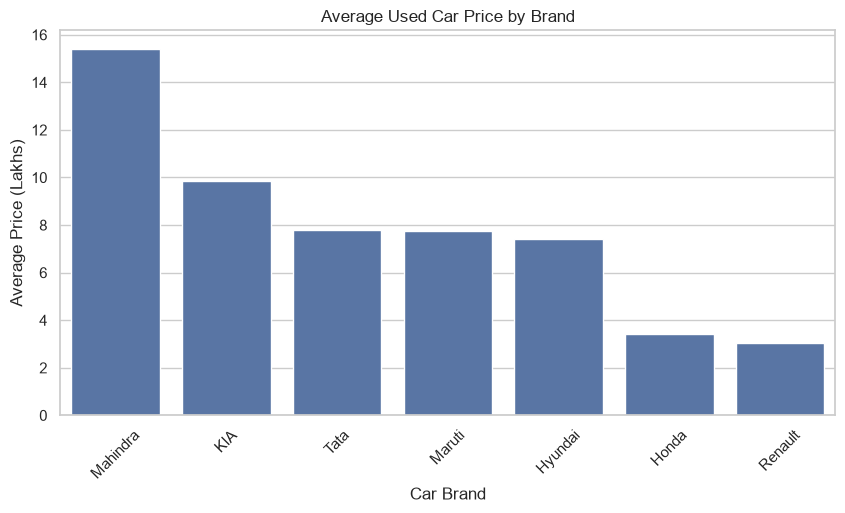

In [77]:
# Brand-wise Average Price
plt.figure(figsize=(10,5))

brand_price = df.groupby("Brand")["Price_Lakhs"].mean().sort_values(ascending=False)

sns.barplot(x=brand_price.index, y=brand_price.values)

plt.title("Average Used Car Price by Brand")
plt.xlabel("Car Brand")
plt.ylabel("Average Price (Lakhs)")
plt.xticks(rotation=45)

plt.show()

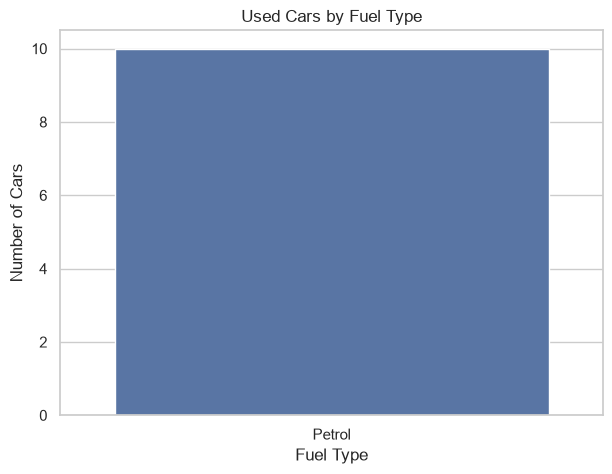

In [78]:
# fuel type distribution
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="Fuel_Type")

plt.title("Used Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")

plt.show()

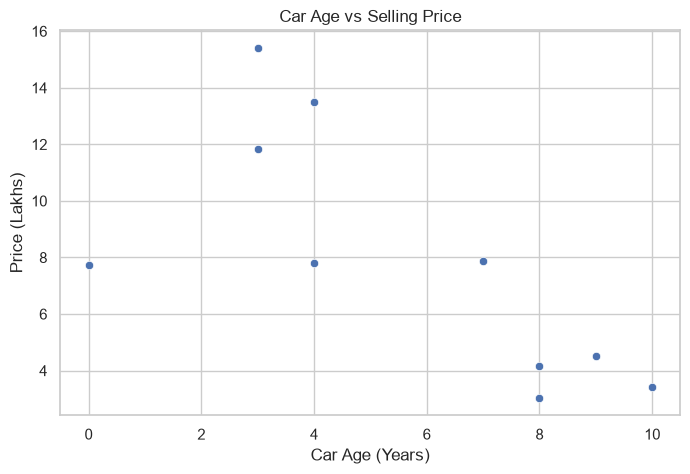

In [79]:
# Car Age vs Price
plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x="Car_Age", y="Price_Lakhs")

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Price (Lakhs)")

plt.show()

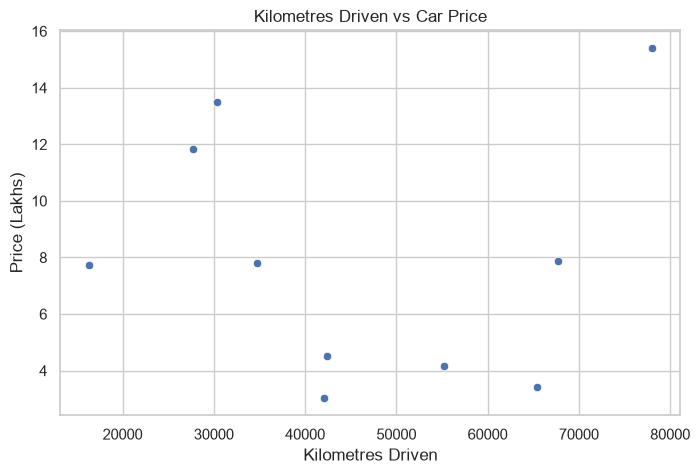

In [80]:
# Kilometres Driven vs Price
plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x="KM_Driven", y="Price_Lakhs")

plt.title("Kilometres Driven vs Car Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Price (Lakhs)")

plt.show()

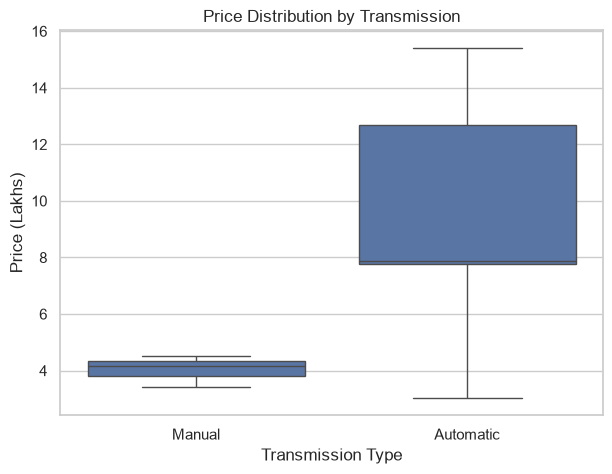

In [81]:
# Transmission-wise Price Comparison
plt.figure(figsize=(7,5))

sns.boxplot(data=df, x="Transmission", y="Price_Lakhs")

plt.title("Price Distribution by Transmission")
plt.xlabel("Transmission Type")
plt.ylabel("Price (Lakhs)")

plt.show()

In [82]:
# Business Insights

In [83]:
# Most expensive car
most_expensive = df.loc[df["Price"].idxmax()]

print("Most Expensive Car:", most_expensive["Car_Name"])
print("Brand:", most_expensive["Brand"])
print("Price:", most_expensive["Price_Lakhs"], "Lakhs")

Most Expensive Car: Mahindra XUV700
Brand: Mahindra
Price: 15.41443 Lakhs


In [84]:
# Cheapest car
cheapest = df.loc[df["Price"].idxmin()]

print("Cheapest Car:", cheapest["Car_Name"])
print("Brand:", cheapest["Brand"])
print("Price:", cheapest["Price_Lakhs"], "Lakhs")

Cheapest Car: Renault Kwid
Brand: Renault
Price: 3.03871 Lakhs


In [85]:
# Average used car price
print("Average Car Price:", round(df["Price_Lakhs"].mean(), 2), "Lakhs")

Average Car Price: 7.93 Lakhs


In [86]:
# Most popular brand
print(df["Brand"].value_counts())

Brand
Hyundai     3
KIA         2
Honda       1
Maruti      1
Tata        1
Mahindra    1
Renault     1
Name: count, dtype: int64


In [87]:
# Average kilometres driven
print("Average KM Driven:", round(df["KM_Driven"].mean(), 0))

Average KM Driven: 45998.0


In [95]:
# Which car age group has the highest average price?
df["Age_Group"] = pd.cut(
    df["Car_Age"],
    bins=[-1, 3, 6, 10, 100],
    labels=["0-3 Years", "4-6 Years", "7-10 Years", "Above 10 Years"]
)

age_analysis = df.groupby("Age_Group", observed=True)["Price_Lakhs"].mean()

print(age_analysis)

Age_Group
0-3 Years     11.659620
4-6 Years     10.654720
7-10 Years     4.607782
Name: Price_Lakhs, dtype: float64


In [96]:
# Which brand offers the most affordable cars?
brand_analysis = df.groupby("Brand").agg(
    Average_Price=("Price_Lakhs", "mean"),
    Number_of_Cars=("Car_Name", "count")
).sort_values(by="Average_Price")

print(brand_analysis)

          Average_Price  Number_of_Cars
Brand                                  
Renault        3.038710               1
Honda          3.430620               1
Hyundai        7.398587               3
Maruti         7.731490               1
Tata           7.802440               1
KIA            9.856880               2
Mahindra      15.414430               1


In [97]:
# Which cars have high kilometres but low prices?
df.sort_values(
    by=["KM_Driven", "Price_Lakhs"],
    ascending=[False, True]
)[["Car_Name", "KM_Driven", "Price_Lakhs"]]

,Car_Name,KM_Driven,Price_Lakhs
7,Mahindra XUV700,78032,15.41443
9,KIA SELTOS,67736,7.88082
2,Honda Amaze,65446,3.43062
0,Hyundai Grand i10,55214,4.16670
4,Hyundai Elite i20,42399,4.52206
8,Renault Kwid,42066,3.03871
6,Tata NEXON,34694,7.80244
5,Hyundai Creta,30399,13.50700
1,KIA CARENS,27724,11.83294
3,Maruti Swift,16275,7.73149


In [98]:
# Compare ownership and resale prices
ownership_analysis = df.groupby("Ownership")["Price_Lakhs"].mean()

print(ownership_analysis)

Ownership
1    8.47650
2    3.03871
Name: Price_Lakhs, dtype: float64


In [99]:
# Identify cars priced above the dataset average
average_price = df["Price_Lakhs"].mean()

df["Price_Category"] = np.where(
    df["Price_Lakhs"] > average_price,
    "Above Average",
    "Below Average"
)

print(df[["Car_Name", "Price_Lakhs", "Price_Category"]])

            Car_Name  Price_Lakhs Price_Category
0  Hyundai Grand i10      4.16670  Below Average
1         KIA CARENS     11.83294  Above Average
2        Honda Amaze      3.43062  Below Average
3       Maruti Swift      7.73149  Below Average
4  Hyundai Elite i20      4.52206  Below Average
5      Hyundai Creta     13.50700  Above Average
6         Tata NEXON      7.80244  Below Average
7    Mahindra XUV700     15.41443  Above Average
8       Renault Kwid      3.03871  Below Average
9         KIA SELTOS      7.88082  Below Average


### Conclusion

The Cars24 Used Car Market Analysis project helped explore used car listings and understand different factors affecting their resale prices using Python.

Through data collection, data cleaning, exploratory data analysis (EDA), and visualization, several insights were identified:

1. The average listed car price in the collected dataset is approximately ₹7.93 lakhs.
2. The Mahindra XUV700 is the most expensive car, priced at approximately ₹15.41 lakhs.
3. The Renault Kwid is the most affordable car, priced at approximately ₹3.03 lakhs.
4. Hyundai has the highest number of listings in the collected dataset.
5. Automatic cars have a higher average listed price than manual cars in this sample.
6. The average kilometres driven across the listed cars is approximately 45,998 km.
7. Car age and kilometres driven provide useful variables for exploring used car pricing patterns.

Overall, this project provided practical experience in Python, web scraping, data manipulation, exploratory data analysis, and data visualization. It also demonstrated how data analysis can help understand used car market trends and support informed buying and selling decisions.